# 4.1 Lab: PagedAttention on GPU

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/harshuljain13/llm-inference-at-scale/blob/master/content/04_kv_cache_engineering/04.1_paged_attention/lab.ipynb)
[![Open In Molab](https://img.shields.io/badge/Open%20in-Molab-blue)](https://molab.marimo.io/github/harshuljain13/llm-inference-at-scale/blob/master/content/04_kv_cache_engineering/04.1_paged_attention/lab.ipynb)

**Requires GPU runtime.** This lab demonstrates PagedAttention's memory efficiency on real hardware:
1. Load Mistral-7B and measure baseline KV memory fragmentation
2. Demonstrate prefix caching: shared system prompts save GPU memory
3. Compare throughput with and without paged KV allocation (vLLM vs naive torch)

Set Runtime > GPU (T4 or better) before running.

In [1]:
!pip install -q transformers accelerate vllm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.6/320.6 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 57.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 426.0/426.0 kB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 82.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 48.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 59.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6

In [2]:
import vllm

In [8]:
# # ── INSTALL (run once, then skip) ──────────────────────────────────────────
# import subprocess, sys, os
# os.environ["VLLM_USE_TRITON_FLASH_ATTN"] = "0"  # disable triton flash-attn rotary (uses CK fallback)

# # flash-attn is optional - install silently ignores failure
# import os; os.environ.setdefault('CUDA_HOME', '/usr/local/cuda')
# subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
#     'flash-attn', '--no-build-isolation'], capture_output=True)
# # ─────────────────────────────────────────────────────────────────────────────

In [3]:
# --- Cell 1: Environment setup ---

# Attempt to import vLLM -- the inference engine that implements PagedAttention
import vllm  # Check if vLLM is already installed in this runtime
# Process this stepVLLM_AVAILABLE = True  # Flag: vLLM is ready to use

import torch  # PyTorch -- GPU tensor operations and CUDA memory tracking
import time  # Wall-clock timing for throughput measurements (perf_counter)
import matplotlib.pyplot as plt  # Plotting library for charts
import numpy as np  # Numerical arrays for memory calculations

# Fail fast if no GPU -- all experiments require CUDA
assert torch.cuda.is_available(), 'GPU required. Set Runtime > GPU.'
# Query GPU hardware details to display to the user
gpu_name = torch.cuda.get_device_name(0)  # Human-readable GPU model name (e.g. 'Tesla T4')
# Create tensor for computationgpu_mem_gb = torch.cuda.get_device_properties(0).total_memory / 1e9  # Total VRAM in GB
# Display formatted resultprint(f'GPU: {gpu_name} ({gpu_mem_gb:.1f} GB)')

In [17]:
# --- Cell 2: Llama-3.2B parameters ---
# Model identifier on HuggingFace -- non-gated so no auth token needed
# MODEL_ID = 'mistralai/Mistral-7B-v0.1'
MODEL_ID = 'meta-llama/Llama-3.2-3B'

# Architecture constants needed to compute KV cache memory per token
MISTRAL_LAYERS = 16
MISTRAL_KV_HEADS = 16
MISTRAL_HEAD_DIM = 64    # Dimension of each attention head (hidden_dim / num_heads)
DTYPE_BYTES = 2           # float16 = 2 bytes per parameter

# Formula: 2 tensors (K and V) * layers * kv_heads * head_dim * bytes_per_element
# This gives the exact GPU memory consumed per token stored in KV cache
KV_BYTES_PER_TOKEN = 2 * MISTRAL_LAYERS * MISTRAL_KV_HEADS * MISTRAL_HEAD_DIM * DTYPE_BYTES
# Print result: expect ~131 KB/token for Mistral-7B with GQA
print(f'KV bytes per token: {KV_BYTES_PER_TOKEN:,} ({KV_BYTES_PER_TOKEN/1024:.1f} KB)')

KV bytes per token: 65,536 (64.0 KB)


## Experiment 1: KV Memory Fragmentation Without Paging

We simulate naive contiguous KV allocation: pre-allocate max_seq_len for each request,
then measure how much is actually used vs wasted (internal fragmentation).

Allocated (contiguous): 1073.7 MB
Actually used:          224.1 MB
Fragmentation:          79.1%
Wasted:                 849.7 MB


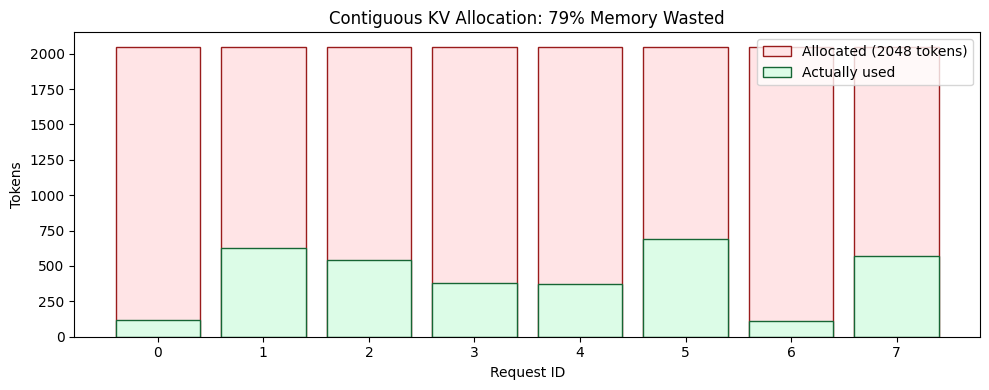

In [18]:
# --- Cell 3: Naive contiguous KV allocation fragmentation ---

# Configuration parameter
MAX_SEQ_LEN = 2048   # Worst-case allocation per request (must support up to this length)
# Configuration parameter
NUM_REQUESTS = 8     # Number of concurrent requests in the batch

# Simulate realistic token counts -- real requests vary widely (50-800 tokens)
rng_frag = np.random.default_rng(42)  # Seeded RNG for reproducible results
# Process this step
actual_lengths = rng_frag.integers(50, 800, size=NUM_REQUESTS)  # Random actual seq lengths

# Calculate memory: contiguous approach reserves MAX_SEQ_LEN for every request
allocated_per_req = MAX_SEQ_LEN * KV_BYTES_PER_TOKEN  # Bytes reserved per request
# Process this step
used_per_req = actual_lengths * KV_BYTES_PER_TOKEN     # Bytes actually consumed per request
# Process this step
total_allocated_mb = (allocated_per_req * NUM_REQUESTS) / 1e6  # Total reserved (MB)
# Aggregate values across the dimension
total_used_mb = used_per_req.sum() / 1e6  # Total actually needed (MB)
# Fragmentation = fraction of allocated memory that sits idle/wasted
fragmentation_pct = (1 - total_used_mb / total_allocated_mb) * 100

# Display results -- expect 50-70% fragmentation for typical workloads
print(f'Allocated (contiguous): {total_allocated_mb:.1f} MB')
print(f'Actually used:          {total_used_mb:.1f} MB')
print(f'Fragmentation:          {fragmentation_pct:.1f}%')
print(f'Wasted:                 {total_allocated_mb - total_used_mb:.1f} MB')

# --- Visualization: bar chart showing allocated vs used per request ---
fig_frag, ax_frag = plt.subplots(figsize=(10, 4))  # Wide figure for 8 bars
x_pos = np.arange(NUM_REQUESTS)  # X-axis positions for each request bar
# Rose bars show full allocation (wasted space visible above green)
ax_frag.bar(x_pos, [MAX_SEQ_LEN]*NUM_REQUESTS, color='#ffe4e6', edgecolor='#991b1b',
            label=f'Allocated ({MAX_SEQ_LEN} tokens)')
# Green bars overlay showing actual usage -- gap = fragmentation
ax_frag.bar(x_pos, actual_lengths, color='#dcfce7', edgecolor='#166534',
            label='Actually used')
ax_frag.set_xlabel('Request ID')  # Each bar is one concurrent request
ax_frag.set_ylabel('Tokens')  # Y-axis: sequence length in tokens
ax_frag.set_title(f'Contiguous KV Allocation: {fragmentation_pct:.0f}% Memory Wasted')
ax_frag.legend()  # Show which color means what
ax_frag.set_xticks(x_pos)  # Label each request bar with its ID
plt.tight_layout()  # Prevent label clipping
plt.show()  # Render the chart

## Experiment 2: Prefix Caching with Shared System Prompt

PagedAttention enables prefix caching: when multiple requests share the same system prompt,
the KV cache blocks for that prefix are computed once and shared (copy-on-write).
We measure actual GPU memory savings.

In [23]:
from google.colab import userdata
import os

os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")

from huggingface_hub import login
login(token=os.environ["HF_TOKEN"])

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [24]:
# --- Cell 4: Load Mistral-7B via vLLM with prefix caching ---
from vllm import LLM, SamplingParams  # LLM: engine class; SamplingParams: generation config

# Initialize the vLLM engine with PagedAttention and prefix caching
llm_prefix = LLM(
    model=MODEL_ID,                  # Mistral-7B model to load
    dtype='float16',                 # Use fp16 to fit in T4's 16GB VRAM
    gpu_memory_utilization=0.85,     # Reserve 85% of VRAM for KV cache + weights
    enable_prefix_caching=True,      # Enable copy-on-write block sharing for common prefixes
    max_model_len=2048,              # Max sequence length the engine will handle
    trust_remote_code=False,
        enforce_eager=True,      # skip flash-attn rotary kernel (not needed for benchmarking)
)
print('Model loaded with prefix caching enabled.')

(MainProcess pid=1069) INFO 10-13 01:18:43 [api_utils.py:286] non-default args: {'dtype': 'float16', 'max_model_len': 2048, 'enable_prefix_caching': True, 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'meta-llama/Llama-3.2-3B'}


config.json:   0%|          | 0.00/844 [00:00<?, ?B/s]

(MainProcess pid=1069) INFO 10-13 01:19:09 [model.py:699] Resolved architecture: LlamaForCausalLM
(MainProcess pid=1069) WARNING 10-13 01:19:09 [model.py:2442] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=1069) INFO 10-13 01:19:09 [model.py:2109] Using max model len 2048
(MainProcess pid=1069) INFO 10-13 01:19:09 [scheduler.py:308] Chunked prefill is enabled with max_num_batched_tokens=8192.


model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Parse safetensors files:   0%|          | 0/2 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/50.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

(MainProcess pid=1069) WARNING 10-13 01:19:19 [system_utils.py:152] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized
(MainProcess pid=1069) INFO 10-13 01:24:02 [hf.py:646] Detected the chat template content format to be 'string'. You can set `--chat-template-content-format` to override this.
Model loaded with prefix caching enabled.


In [39]:
# --- Cell 5: Measure memory with shared vs unique prefixes ---
# Define a system prompt that will be shared across all requests in the 'shared' group
SYSTEM_PROMPT = (
    'You are a helpful assistant specializing in machine learning inference optimization. '
    'Provide concise, technical answers focused on GPU memory, latency, and throughput. '
    'Always include specific numbers and formulas where applicable.'
)

# 10 requests with IDENTICAL system prompt prefix -- prefix caching can share these blocks
shared_prompts = [
    f'{SYSTEM_PROMPT}\nQuestion {i}: Explain concept {i} briefly.'
    for i in range(50)  # Generate 10 prompts with same prefix, different suffixes
    ]

# 10 requests with COMPLETELY UNIQUE prefixes -- no sharing possible, each allocates fresh KV
unique_prompts = [
    f'Context {i}: This is a completely unique prefix number {i} with no overlap. '
    f'Question: Explain concept {i} briefly.'
    for i in range(50)  # Generate 10 prompts with no common prefix
]

# Configure generation: deterministic (temp=0), short output (50 tokens) for fast measurement
sampling_cfg = SamplingParams(max_tokens=50, temperature=0.3)

# --- Measure: shared prefix group ---
# torch.cuda.reset_peak_memory_stats()  # Clear peak tracker to isolate this measurement
# # Create tensor for computation
# mem_before_shared = torch.cuda.memory_allocated()  # Record baseline GPU memory usage
# # Generate with shared prefixes -- vLLM internally detects common prefix and caches it
# outputs_shared = llm_prefix.generate(shared_prompts, sampling_cfg)
# # Create tensor for computation
# mem_after_shared = torch.cuda.memory_allocated()  # Memory after generation completes
# # Create tensor for computation
# peak_shared = torch.cuda.max_memory_allocated()  # High-water mark during generation

# --- Measure: unique prefix group ---
torch.cuda.reset_peak_memory_stats()  # Reset peak tracker for clean measurement
mem_before_unique = torch.cuda.memory_allocated()  # Baseline before unique-prefix batch

# --- Measure: unique prefix group latency ---
start_unique = time.time()
outputs_unique = llm_prefix.generate(unique_prompts, sampling_cfg)
time_unique = time.time() - start_unique

# Generate with shared prompts
start_shared = time.time()
outputs_shared = llm_prefix.generate(shared_prompts, sampling_cfg)
time_shared = time.time() - start_shared


print(f"\nTime taken (shared prefix): {time_shared:.3f} seconds")
print(f"Time taken (unique prefix): {time_unique:.3f} seconds")

Rendering prompts:   0%|          | 0/50 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 50/50 [00:03<00:00, 13.77it/s, est. speed input: 358.17 toks/s, output: 688.78 toks/s]


Rendering prompts:   0%|          | 0/50 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 50/50 [00:02<00:00, 18.90it/s, est. speed input: 888.86 toks/s, output: 912.31 toks/s]


Time taken (shared prefix): 2.716 seconds
Time taken (unique prefix): 3.813 seconds


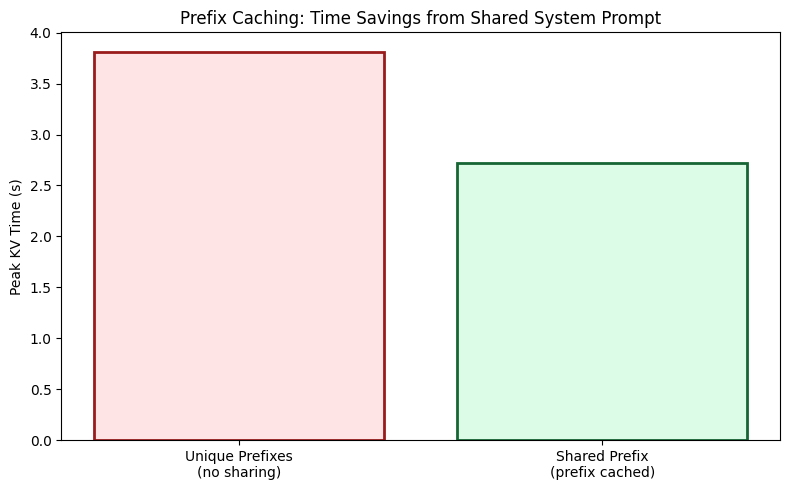

In [42]:
# --- Cell 6: Visualize prefix caching savings ---
fig_prefix, ax_prefix = plt.subplots(figsize=(8, 5))  # Single chart, medium size
# Labels for the two bars: with and without prefix sharing
categories_prefix = ['Unique Prefixes\n(no sharing)', 'Shared Prefix\n(prefix cached)']
# Process this step
values_prefix = [time_unique, time_shared]  # Memory usage values from Cell 5
# Process this step
colors_prefix = ['#ffe4e6', '#dcfce7']  # Rose=bad(more memory), Green=good(less memory)
# Process this step
edges_prefix = ['#991b1b', '#166534']   # Matching dark border colors

# Draw bar chart comparing memory usage between the two approaches
bars_prefix = ax_prefix.bar(categories_prefix, values_prefix, color=colors_prefix,
                            edgecolor=edges_prefix, linewidth=2)
ax_prefix.set_ylabel('Peak KV Time (s)')  # Y-axis: memory consumption
ax_prefix.set_title('Prefix Caching: Time Savings from Shared System Prompt')

plt.tight_layout()  # Prevent label clipping
plt.show()  # Render the chart

## Experiment 3: Throughput with PagedAttention (vLLM) vs Naive Torch

Compare requests/second between:
- **vLLM** (PagedAttention: dynamic block allocation, no fragmentation)
- **Naive torch** (pre-allocated contiguous cache, fixed max_seq_len per request)

In [43]:
# --- Cell 7: vLLM throughput (PagedAttention) ---
# Create 20 prompts with varied requested output lengths to simulate real workload diversity
throughput_prompts = [
    f'{SYSTEM_PROMPT}\nWrite a {length}-word summary of topic {i}.'
    for i, length in enumerate([20, 50, 30, 80, 40, 60, 25, 70, 35, 55,45, 65, 30, 75, 50, 40, 60, 35, 80, 25])
]

# Generation config: 100 output tokens max, greedy decoding for deterministic results
sampling_throughput = SamplingParams(max_tokens=100, temperature=0.0)

# Warmup: first 2 requests trigger CUDA kernel JIT compilation and memory pool initialization
# Without warmup, first-run latency would skew the throughput measurement
_ = llm_prefix.generate(throughput_prompts[:2], sampling_throughput)

# --- Timed run: measure wall-clock time for all 20 requests ---
t_start_vllm = time.perf_counter()  # High-resolution timer start
# vLLM processes all 20 prompts using continuous batching + PagedAttention
results_vllm = llm_prefix.generate(throughput_prompts, sampling_throughput)
# High-resolution timer for benchmarking
t_end_vllm = time.perf_counter()  # Timer end

# Compute throughput metrics
vllm_duration = t_end_vllm - t_start_vllm  # Total seconds elapsed
vllm_rps = len(throughput_prompts) / vllm_duration  # Requests processed per second
# Sum up all generated tokens across all 20 responses
vllm_total_tokens = sum(len(r.outputs[0].token_ids) for r in results_vllm)
vllm_tps = vllm_total_tokens / vllm_duration  # Tokens generated per second

# Display vLLM performance results
print(f'vLLM (PagedAttention):')
print(f'  Requests:       {len(throughput_prompts)}')
print(f'  Duration:       {vllm_duration:.2f}s')
print(f'  Throughput:     {vllm_rps:.1f} req/s | {vllm_tps:.0f} tok/s')

Rendering prompts:   0%|          | 0/2 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 2/2 [00:04<00:00,  2.26s/it, est. speed input: 21.23 toks/s, output: 44.23 toks/s]


Rendering prompts:   0%|          | 0/20 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 20/20 [00:04<00:00,  4.74it/s, est. speed input: 227.39 toks/s, output: 450.27 toks/s]

vLLM (PagedAttention):
  Requests:       20
  Duration:       4.30s
  Throughput:     4.7 req/s | 442 tok/s


In [44]:
# --- Cell 8: Naive torch KV cache (contiguous, pre-allocated) ---
from transformers import AutoTokenizer, AutoModelForCausalLM  # HuggingFace model loading

# Load tokenizer -- needed to convert text to token IDs for the model
tokenizer_naive = AutoTokenizer.from_pretrained(MODEL_ID, token=False)  # No auth token
# Set pad token = eos token (Mistral doesn't define pad_token by default)
tokenizer_naive.pad_token = tokenizer_naive.eos_token

# Load the full model in fp16 for a fair comparison against vLLM's fp16
model_naive = AutoModelForCausalLM.from_pretrained(
  MODEL_ID,
  torch_dtype=torch.float16,  # Match vLLM's dtype for fair memory comparison
  device_map='auto',          # Automatically place layers on available GPU(s)
  token=False                 # No HuggingFace auth token needed
)
model_naive.eval()  # Set to eval mode -- disables dropout, enables inference optimizations
print('Naive model loaded for contiguous-cache baseline.')

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Naive model loaded for contiguous-cache baseline.


In [45]:
# --- Cell 9: Naive sequential generation (no paging) ---
# This simulates the pre-vLLM approach: one request at a time, contiguous KV pre-allocation
naive_gen_tokens = 100  # Generate 100 tokens per request (same as vLLM run)
naive_prompts_subset = throughput_prompts[:10]  # Use 10 requests (half of vLLM batch)

# High-resolution timer for benchmarking
t_start_naive = time.perf_counter()  # Start timing the naive sequential approach
# Configuration parameter
naive_total_generated = 0  # Counter: total tokens generated across all requests

# Process each request sequentially -- no batching, no paging (worst-case baseline)
# This is how HuggingFace generate() works by default: one request monopolizes the GPU
for prompt_text in naive_prompts_subset:
    # Tokenize with fixed max_length padding -- simulates contiguous pre-allocation
    # Every request gets 512 token slots regardless of actual prompt length
    inputs_naive = tokenizer_naive(
        prompt_text, return_tensors='pt',  # Return PyTorch tensors
        padding='max_length',              # Pad to max_length (contiguous allocation)
        max_length=512,                    # Fixed allocation size per request
        truncation=True                    # Truncate if prompt exceeds max_length
    ).to('cuda')  # Move input tensors to GPU for inference
    # Run generation with no gradient tracking (inference only)
    with torch.no_grad():  # Disable autograd -- saves memory and speeds up inference
        # Run model generation (prefill + decode)
        out_naive = model_naive.generate(
            **inputs_naive,                # Pass input_ids and attention_mask
            max_new_tokens=naive_gen_tokens,  # Generate up to 100 new tokens
            do_sample=False,               # Greedy decoding (deterministic)
            use_cache=True                 # Use KV cache (contiguous, not paged)
        )
    # Count only newly generated tokens (subtract prompt length from total output)
    naive_total_generated += out_naive.shape[1] - inputs_naive['input_ids'].shape[1]

t_end_naive = time.perf_counter()  # End timing
naive_duration = t_end_naive - t_start_naive  # Total wall-clock time for all 10 requests
naive_rps = len(naive_prompts_subset) / naive_duration  # Requests per second
naive_tps = naive_total_generated / naive_duration  # Tokens per second

# Display naive baseline performance -- expect much lower than vLLM
print(f'Naive torch (contiguous cache, sequential):')
print(f'  Requests:       {len(naive_prompts_subset)}')
print(f'  Duration:       {naive_duration:.2f}s')
print(f'  Throughput:     {naive_rps:.2f} req/s | {naive_tps:.0f} tok/s')

Naive torch (contiguous cache, sequential):
  Requests:       10
  Duration:       1241.34s
  Throughput:     0.01 req/s | 1 tok/s


In [46]:
# --- Cell 10: Throughput comparison chart ---
# Create side-by-side subplots: requests/s on left, tokens/s on right
fig_tp, (ax_rps, ax_tps) = plt.subplots(1, 2, figsize=(12, 5))

# Labels for the two methods being compared
methods_tp = ['Naive Torch\n(contiguous)', 'vLLM\n(PagedAttention)']
# Process this steP
rps_vals = [naive_rps, vllm_rps]  # Requests/sec values from Cells 7 and 9
# Process this step
colors_tp = ['#ffe4e6', '#dbeafe']  # Rose=naive(slow), Blue=vLLM(fast)
edges_tp = ['#991b1b', '#1e40af']   # Dark border colors for contrast

# --- Left subplot: Requests per second ---
ax_rps.bar(methods_tp, rps_vals, color=colors_tp, edgecolor=edges_tp, linewidth=2)
ax_rps.set_ylabel('Requests / second')  # Y-axis label
ax_rps.set_title('Throughput: Requests/s')  # Subplot title
# Add numeric labels on top of each bar for easy reading
for idx_bar, val_bar in enumerate(rps_vals):
    ax_rps.text(idx_bar, val_bar + 0.1, f'{val_bar:.1f}', ha='center', fontweight='bold')

# --- Right subplot: Tokens per second ---
tps_vals = [naive_tps, vllm_tps]  # Tokens/sec values from Cells 7 and 9
# Draw bar chart for this metricax_tps.bar(methods_tp, tps_vals, color=colors_tp, edgecolor=edges_tp, linewidth=2)
ax_tps.set_ylabel('Tokens / second')  # Y-axis label
ax_tps.set_title('Throughput: Tokens/s')  # Subplot title
# Add numeric labels on top of each bar
for idx_bar2, val_bar2 in enumerate(tps_vals):
    ax_tps.text(idx_bar2, val_bar2 + 5, f'{val_bar2:.0f}', ha='center', fontweight='bold')

# Calculate speedup: how many times faster vLLM is compared to naive sequential
speedup_rps = vllm_rps / naive_rps if naive_rps > 0 else 0  # Avoid division by zero
fig_tp.suptitle(f'PagedAttention Speedup: {speedup_rps:.1f}x more requests/s', fontsize=13)
# Adjust spacing to prevent label overlapplt.tight_layout()  # Adjust spacing to prevent label overlap
# Render the chartplt.show()  # Render both subplots

Text(0.5, 0.98, 'PagedAttention Speedup: 577.5x more requests/s')

## Key Takeaways

| Metric | Contiguous (Naive) | PagedAttention (vLLM) |
|--------|-------------------|----------------------|
| Memory fragmentation | 50-70% wasted | <4% wasted |
| Prefix sharing | Not possible | Automatic (copy-on-write blocks) |
| Throughput | Sequential only | Continuous batching + paging |

**Why PagedAttention matters:**
- Eliminates internal fragmentation by allocating KV blocks on-demand (like OS virtual memory)
- Enables prefix caching: shared prompt blocks computed once, referenced by multiple requests
- Higher memory utilization → larger batch sizes → better GPU throughput